# Malaysian public transport demand

## Summary
In 2025, reported services sum to 451,121,402 headline rides. This is an observed-service total, not a count of unique passengers or all Malaysian public transport.

MRT Kajang records 92,737,532 rides in 2025, accounting for 20.6% of reported rides and ranking first.

Among full-year comparable services, MRT Putrajaya has the largest 2025 annual increase (+15.7%); Rapid Bus Kuantan has the weakest change (-18.8%).

The fixed four-service rail basket totals 274,490,644 rides in 2025, +8.4% against 2024 and +16.2% against 2019.

## Context and methods
Explore demand, service contribution and temporal patterns from the supplied headline counts. Historical trends use the fixed basket: Ampang, Kajang, Kelana Jaya and Monorail. Service ranking and growth focus on 2025, the latest complete year.

### Assumptions
Shares refer to reported rides, not unique travellers or national market share. Full-year growth requires complete observations in both years; 2026 is partial. Zeros are preserved but need investigation. Service reliability, capacity and journey purpose are not measured, so efficiency and causation cannot be inferred. Source: [data.gov.my](https://data.gov.my/data-catalogue/ridership_headline).

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import RAW_PATH, OUTPUT_DIR, SERVICES, CORE_SERVICES
from src.data_cleaning import clean_data, quality_profile, reshape_data, validate_outputs
pd.set_option('display.max_rows', 16)
pd.set_option('display.max_columns', 10)
pd.set_option('display.width', 120)

import matplotlib.pyplot as plt
from src.analysis import build_analysis
from src.features import daily_totals, monthly_service_metrics
from IPython.display import Image
clean = pd.read_csv(OUTPUT_DIR / 'ridership_clean.csv', parse_dates=['date'])
long = pd.read_csv(OUTPUT_DIR / 'ridership_long.csv', parse_dates=['date'])
evidence = build_analysis(clean, long)
comparison_year = evidence['comparison_year']

## Data
Confirm bounds and observation coverage before comparing demand.

In [2]:
display(pd.read_csv(OUTPUT_DIR / 'quality_profile.csv')[['service_code', 'observed_days', 'missing_pct', 'zero_days']].round(1))

,service_code,observed_days,missing_pct,zero_days
0,bus_rkl,1704,39.1,0
1,bus_rkn,1704,39.1,260
2,bus_rpn,1704,39.1,0
3,rail_lrt_ampang,2800,0.0,0
4,rail_mrt_kajang,2800,0.0,0
5,rail_lrt_kj,2800,0.0,0
6,rail_monorail,2800,0.0,0
7,rail_mrt_pjy,1538,45.1,0
8,rail_lrt_shah_alam,94,96.6,30
9,rail_ets,2147,23.3,0


## Results
### Long-term demand on a fixed basket

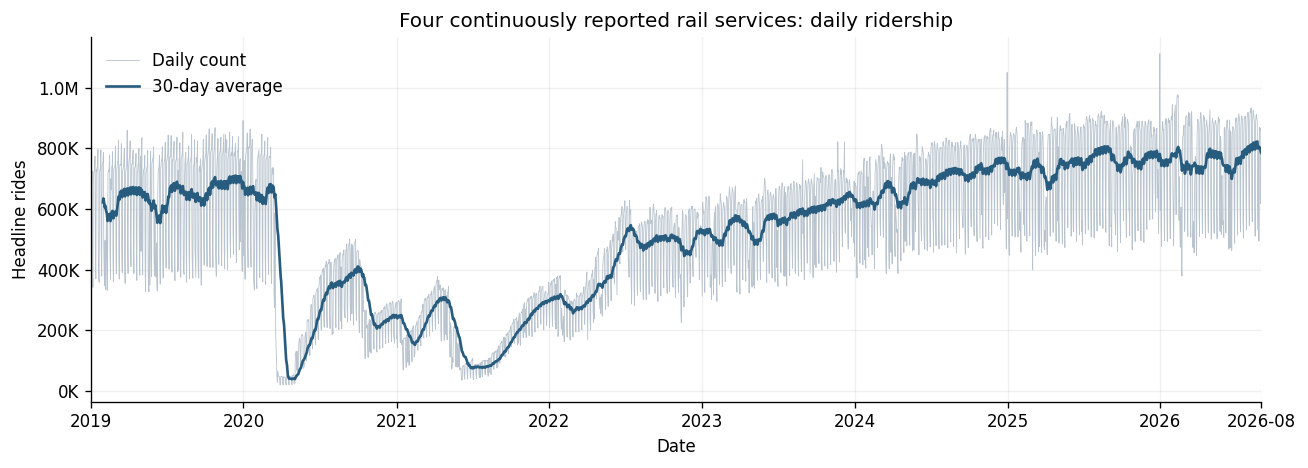

In [3]:
display(Image(filename=str(ROOT / 'images/core_trend.png')))

The fixed four-service rail basket totals 274,490,644 rides in 2025, +8.4% against 2024 and +16.2% against 2019. The basket's lowest full-year total is 70,861,926 in 2021; the data identifies the drop but does not establish its cause.

### Reported totals need a coverage companion
The increase in measured services changes the population being summed. Use this chart for reported volume, and the basket chart for like-for-like history.

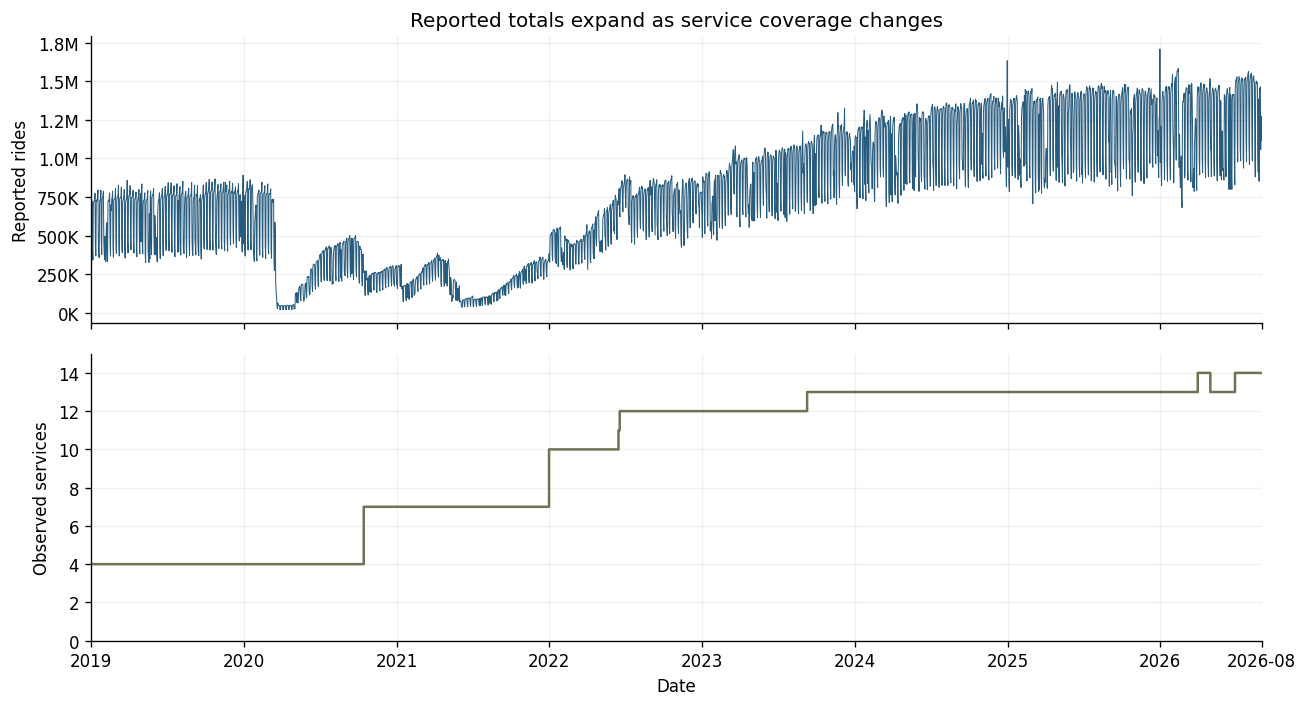

In [4]:
display(Image(filename=str(ROOT / 'images/reported_coverage.png')))

### Which services carry the most rides?

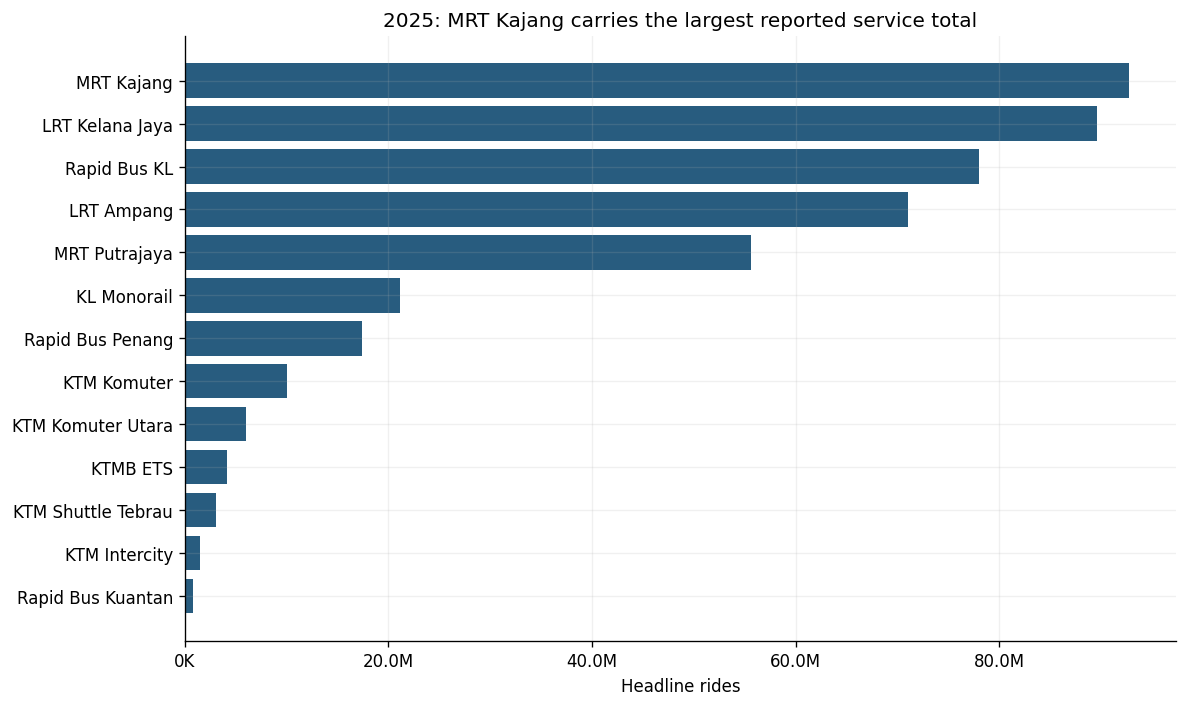

In [5]:
display(Image(filename=str(ROOT / 'images/service_ranking.png')))

MRT Kajang records 92,737,532 rides in 2025, accounting for 20.6% of reported rides and ranking first.

In [6]:
performance = pd.read_csv(ROOT / 'reports/service_performance.csv')
display(performance[['service', 'ridership', 'observed_days', 'share_pct', 'yoy_pct']].round(2))

,service,ridership,observed_days,share_pct,yoy_pct
0,MRT Kajang,92737532.0,365,20.56,9.72
1,LRT Kelana Jaya,89632502.0,365,19.87,5.78
2,Rapid Bus KL,77991484.0,365,17.29,3.89
3,LRT Ampang,71019400.0,365,15.74,10.93
4,MRT Putrajaya,55670064.0,365,12.34,15.68
5,KL Monorail,21101210.0,365,4.68,5.34
6,Rapid Bus Penang,17402492.0,365,3.86,6.96
7,KTM Komuter,10045207.0,365,2.23,-17.55
8,KTM Komuter Utara,6039020.0,365,1.34,9.22
9,KTMB ETS,4174696.0,365,0.93,0.71


### Growth and decline among comparable services

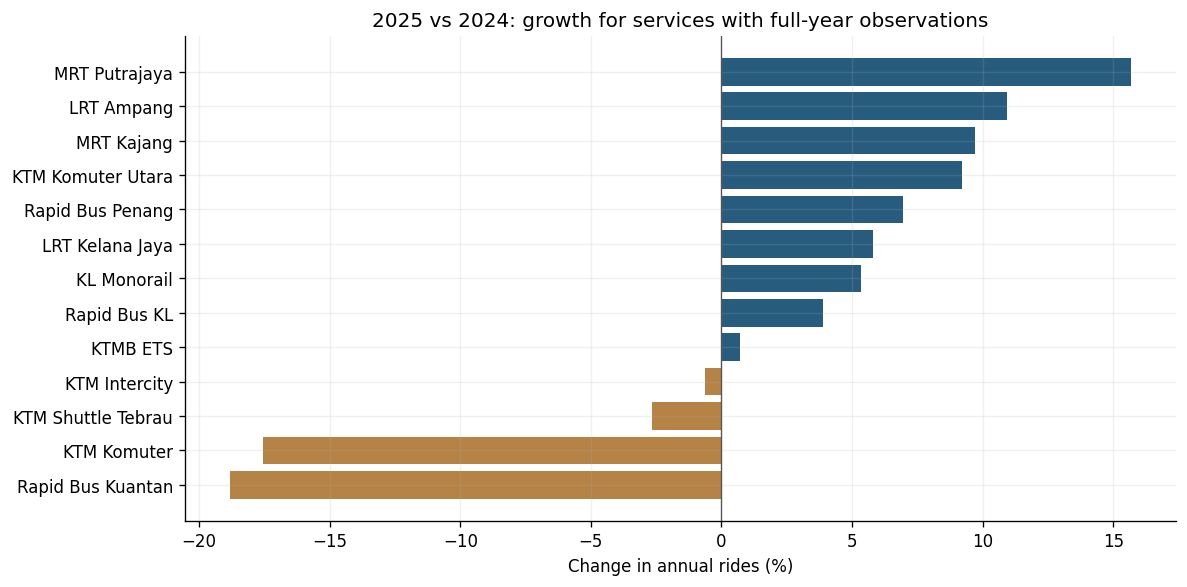

In [7]:
display(Image(filename=str(ROOT / 'images/service_growth.png')))

Among full-year comparable services, MRT Putrajaya has the largest 2025 annual increase (+15.7%); Rapid Bus Kuantan has the weakest change (-18.8%). Kuantan's zero run limits interpretation: the decline may mix demand and reporting/operational changes. Check with the publisher before describing it as a demand loss.

### Mode contribution
The categories are defined in src/config.py. Multiple rail categories are retained to avoid hiding different service patterns.

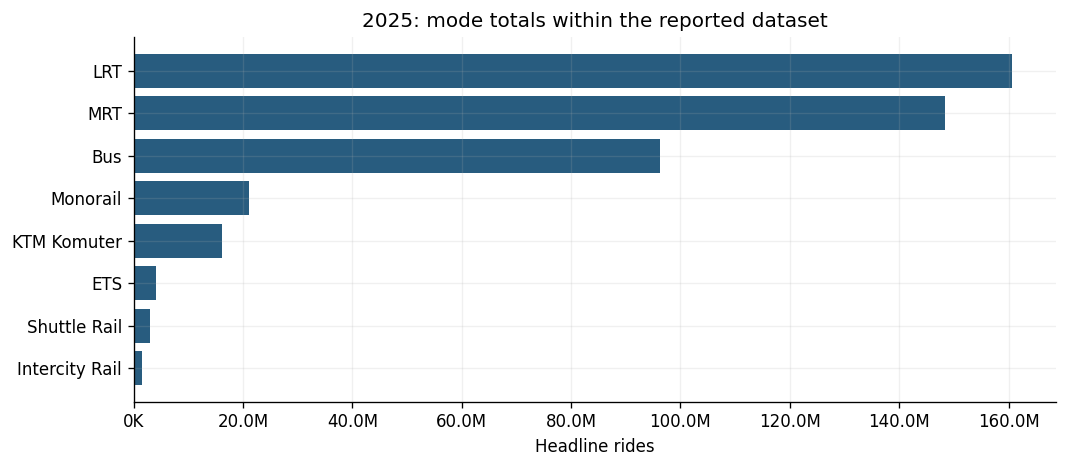

,mode,ridership,reported_share_pct
0,LRT,160651902.0,35.61
1,MRT,148407596.0,32.90
2,Bus,96186015.0,21.32
3,Monorail,21101210.0,4.68
4,KTM Komuter,16084227.0,3.57
5,ETS,4174696.0,0.93
6,Shuttle Rail,3031442.0,0.67
7,Intercity Rail,1484314.0,0.33


In [8]:
display(Image(filename=str(ROOT / 'images/mode_totals.png')))
modes = pd.read_csv(ROOT / 'reports/mode_totals.csv')
modes['reported_share_pct'] = modes.ridership / modes.ridership.sum() * 100
display(modes.round(2))

### Weekday and weekend demand

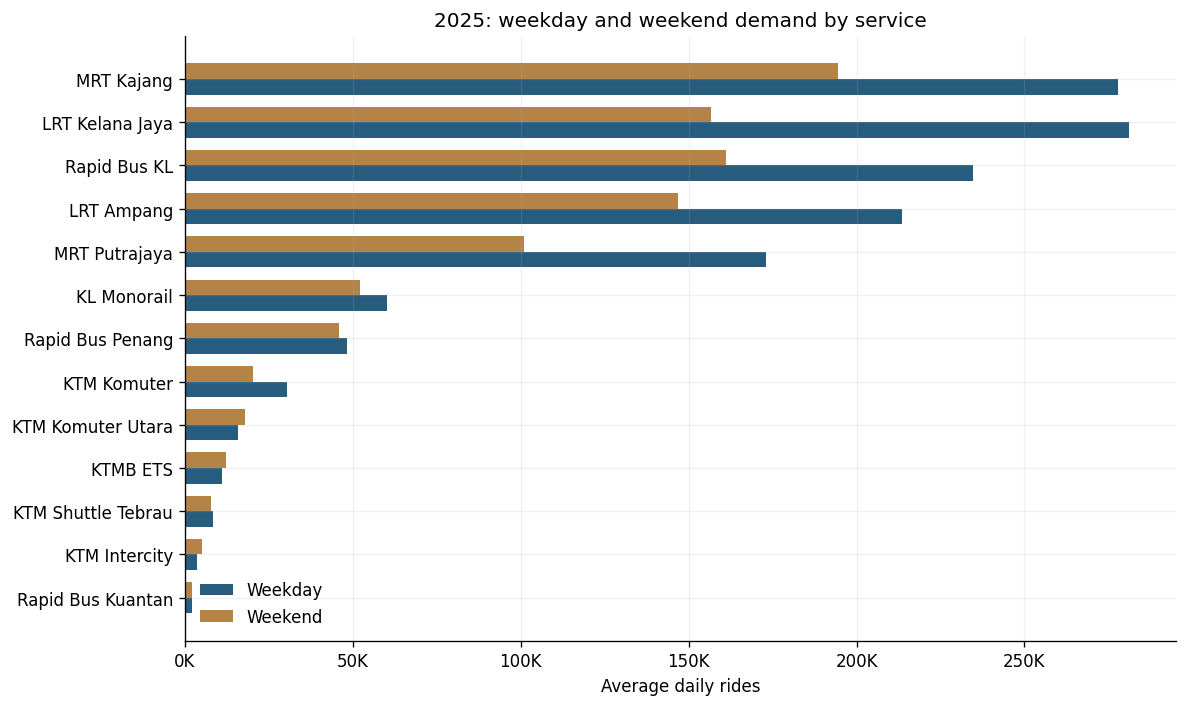

In [9]:
display(Image(filename=str(ROOT / 'images/weekday_weekend.png')))

In 2025, basket weekend daily ridership averages -33.9% relative to weekdays. Commuting is a plausible interpretation; journey purpose is not observed. ETS and commuter services need their own comparisons; a network average should not dictate every service's timetable.

### Monthly pattern across years
Each cell is mean daily ridership, avoiding month-length effects. Blank cells are unavailable. Repeated patterns are a descriptive clue; annual recovery and service changes can confound seasonality.

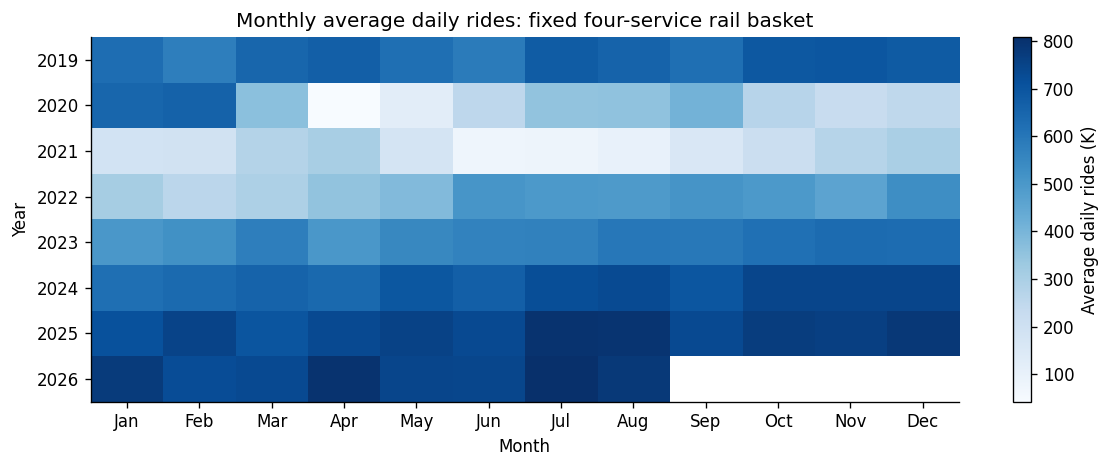

In [10]:
display(Image(filename=str(ROOT / 'images/monthly_patterns.png')))

In 2025, the basket's highest monthly daily average occurs in month 7 (798,960 rides/day); its lowest occurs in month 3 (700,174). This describes one year rather than proving recurring seasonality.

### Annual comparison excludes 2026

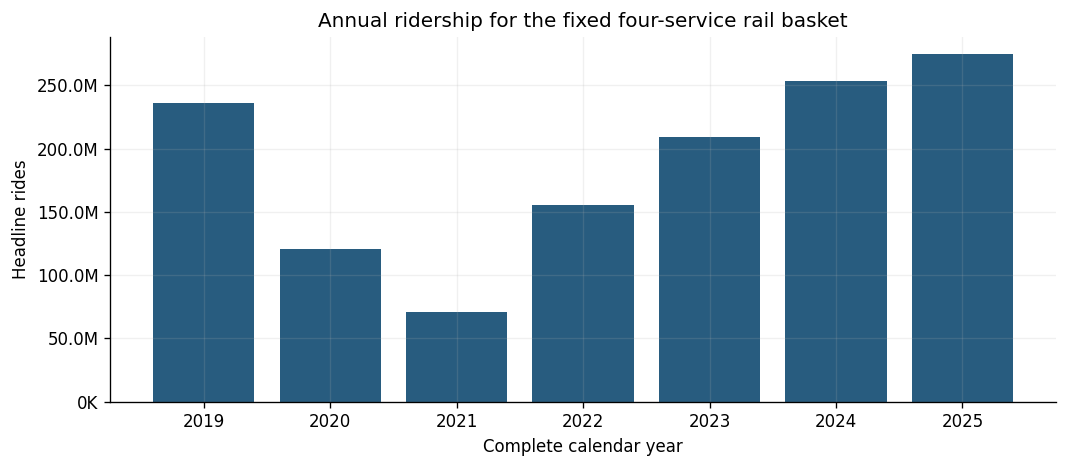

,year,sum,mean,count,expected_days,complete,yoy_pct
0,2019,236293739,647380.11,365,365,True,NaN
1,2020,120334616,328783.10,366,366,True,-49.07
2,2021,70861926,194142.26,365,365,True,-41.11
3,2022,155183375,425159.93,365,365,True,118.99
4,2023,208963252,572502.06,365,365,True,34.66
5,2024,253309598,692102.73,366,366,True,21.22
6,2025,274490644,752029.16,365,365,True,8.36
7,2026,185553224,763593.51,243,365,False,NaN


In [11]:
display(Image(filename=str(ROOT / 'images/annual_core.png')))
display(pd.read_csv(ROOT / 'reports/core_annual.csv').round(2))

### Which services look consistent or volatile?
Daily coefficient of variation describes variability relative to the mean; it mixes weekday patterns, trends and unusual days. It is not a risk score or service-reliability metric. Compare complete 2025 observations.

In [12]:
display(performance[performance.observed_days.eq(365)][['service', 'daily_mean', 'coefficient_of_variation']].sort_values('coefficient_of_variation', ascending=False).round(3))
monthly = monthly_service_metrics(long)
latest = monthly[monthly.month_start.dt.year.eq(comparison_year)]
consistency = latest.groupby('service').agg(comparable_months=('yoy_pct', 'count'), positive_yoy_months=('yoy_pct', lambda s: s.gt(0).sum()), median_yoy_pct=('yoy_pct', 'median'))
display(consistency.sort_values(['positive_yoy_months', 'median_yoy_pct'], ascending=False).round(2))

,service,daily_mean,coefficient_of_variation
11,KTM Intercity,4066.614,0.353
12,Rapid Bus Kuantan,2169.970,0.280
1,LRT Kelana Jaya,245568.499,0.268
4,MRT Putrajaya,152520.723,0.257
7,KTM Komuter,27521.115,0.251
3,LRT Ampang,194573.699,0.195
2,Rapid Bus KL,213675.299,0.192
8,KTM Komuter Utara,16545.260,0.190
0,MRT Kajang,254075.430,0.183
9,KTMB ETS,11437.523,0.144


,comparable_months,positive_yoy_months,median_yoy_pct
service,,,
MRT Putrajaya,12,12,15.84
LRT Ampang,12,12,10.32
MRT Kajang,12,12,10.22
KTM Komuter Utara,12,12,8.66
Rapid Bus Penang,12,12,7.25
KL Monorail,12,12,5.69
LRT Kelana Jaya,12,11,5.53
Rapid Bus KL,12,9,3.53
KTMB ETS,12,6,0.65


Services with positive YoY in all 12 comparable months show sustained observed growth for this year. Services with small annual changes may still vary substantially month to month; avoid labelling them permanently stagnant.

### Unusual observations remain in the data

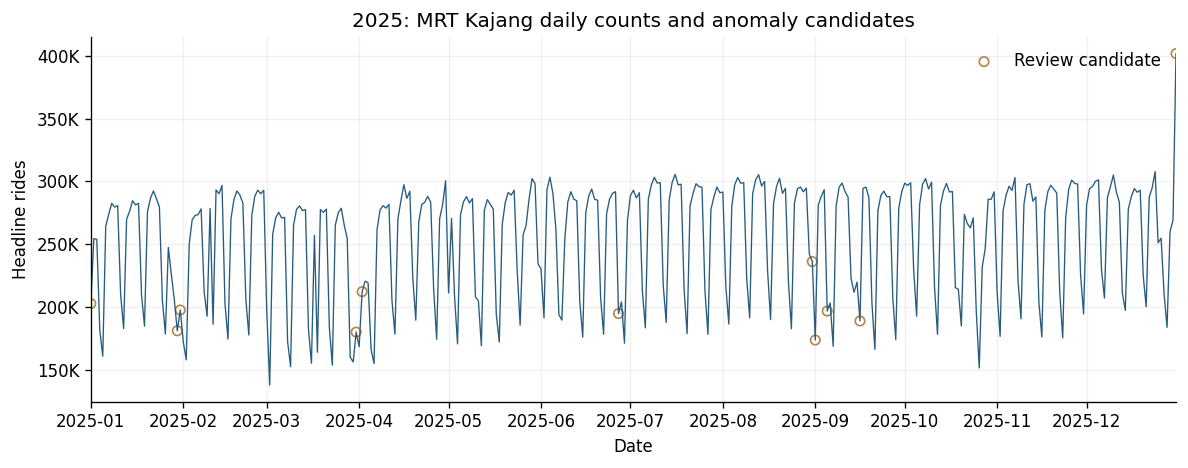

,date,service,ridership,weekday_baseline,anomaly_score
0,2026-08-25,LRT Kelana Jaya,143736.0,305489.88,-67.93
1,2023-03-19,MRT Putrajaya,126977.0,14987.50,63.82
2,2023-03-18,MRT Putrajaya,127158.0,15994.88,60.48
3,2026-02-01,KTM Komuter,87165.0,19859.38,48.72
4,2025-09-01,LRT Kelana Jaya,136334.0,292303.75,-48.63
5,2021-10-16,KTMB ETS,3059.0,228.38,46.66
6,2026-01-31,KTM Komuter,72501.0,19650.75,44.48
7,2026-08-25,MRT Kajang,184354.0,308778.50,-43.97


In [13]:
display(Image(filename=str(ROOT / 'images/anomaly_candidates.png')))
anomalies = pd.read_csv(ROOT / 'reports/anomaly_candidates.csv')
display(anomalies.head(8).round(2))

Across the snapshot, 684 date-service observations meet the documented anomaly review rule; all remain in the analytical data. These flags are screening candidates, not confirmed errors. The rule uses eight preceding matching weekdays, a four-standard-deviation threshold and a 25% relative deviation threshold. Source records, holidays and disruption logs would be needed to distinguish real events from measurement issues.

## Takeaways
- The snapshot spans 2,800 consecutive dates (2019-01-01 to 2026-08-31) and 14 services; 12,193 of 39,200 date-service cells are unreported.

- In 2025, reported services sum to 451,121,402 headline rides. This is an observed-service total, not a count of unique passengers or all Malaysian public transport.

- MRT Kajang records 92,737,532 rides in 2025, accounting for 20.6% of reported rides and ranking first.

- Among full-year comparable services, MRT Putrajaya has the largest 2025 annual increase (+15.7%); Rapid Bus Kuantan has the weakest change (-18.8%).

- The fixed four-service rail basket totals 274,490,644 rides in 2025, +8.4% against 2024 and +16.2% against 2019.

- The basket's lowest full-year total is 70,861,926 in 2021; the data identifies the drop but does not establish its cause.

- In 2025, basket weekend daily ridership averages -33.9% relative to weekdays. Commuting is a plausible interpretation; journey purpose is not observed.

- In 2025, the basket's highest monthly daily average occurs in month 7 (798,960 rides/day); its lowest occurs in month 3 (700,174). This describes one year rather than proving recurring seasonality.

- Across the snapshot, 684 date-service observations meet the documented anomaly review rule; all remain in the analytical data. These flags are screening candidates, not confirmed errors.

Possible operational implication: review whether each service's capacity and frequency align with its day-type demand. Add capacity and timetable data before recommending actual schedule changes. This dataset measures usage, not punctuality, crowding or efficiency.